# NB1 · From tracks to kinematics, behavioral states and time-correlations

Tracking gives positions; behavior lives in what we compute from them. *E. coli* alternates between **runs** (swimming nearly straight) and **tumbles** (short, slow, random reorientations): its **behavioral states**. How a cell combines its states, and changes them in response to its environment, is its **navigation strategy**. Strategies differ between species and between individuals.

This notebook turns positions into quantities that show this:

* **A · Speeds.** Velocity, speed and angular velocity from noisy positions, and the smoothing trade-off.
* **B · State space.** Runs and tumbles as regions in the plane of speed $v$ and angular velocity $\omega$.
* **C · Correlations.** How long a cell remembers its direction.

(Part **D**, from kinematics back to space, is the mean squared displacement in NB2.)

**Data.** One synthetic dataset, `run_tumble`: *E. coli*-like swimmers recorded at 30 frames per second, with localization error and short tracks, like real microscopy data. Because it is synthetic, we also know the *true* state of every cell in every frame, so we can check our methods.

Five stops marked **🔧 Try it** are for hands-on work and discussion in class. Each changes only the cells right below it.

## 0 · Setup
Run this cell first. It loads the packages and the course package `motility` from the folder above `notebooks/`.

### 🔧 Try it 1 · Run the whole notebook
> Choose *Run → Run All Cells*. It takes about 10 s. Every code cell should show a figure or a printout, and none should be red.
>
> If the first cell fails with `ModuleNotFoundError: No module named 'motility'`, switch the kernel to **Python (mcdb5910)** (top-right corner) and run all again. Then come back here and read from the top.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # the course package `motility` is in the folder above notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from motility import io, plotting
from motility import analysis as an
from motility import simulate as sim
from motility.plotting import COLORS, STYLE, GRAY, THEORY_KW

plotting.set_style()
rng = np.random.default_rng(5910)   # fixed seed: everyone gets the same figures

## 1 · The data

One row per detection: which cell (`track_id`), when (`frame`, `t` in s) and where (`x_um`, `y_um` in µm). A JSON file holds the metadata (frame rate, localization noise, simulation parameters). The **truth** table gives the true state of each detection.

In [2]:
df, meta = io.load_dataset("run_tumble")
truth = io.load_truth("run_tumble")
FPS = meta["fps"]                          # frames per second
SIGMA = meta["localization_noise_um"]      # µm, localization noise of every position

print(meta["description"])
print(f"{meta['n_tracks']} tracks, {len(df)} detections, {FPS:.0f} frames per second, "
      f"localization noise {SIGMA} µm")
df.head()

Run-and-tumble swimmers (E. coli-like) in a uniform environment. Each cell has its own swimming speed. Tumbles happen at a constant rate.
400 tracks, 123855 detections, 30 frames per second, localization noise 0.2 µm


,track_id,frame,t,x_um,y_um
0,1,248,8.2667,455.648,411.227
1,1,249,8.3000,456.176,410.757
2,1,250,8.3333,457.026,409.982
3,1,251,8.3667,457.667,409.748
4,1,252,8.4000,458.445,409.392


The simulation parameters (unknown in a real experiment; here they let us check our results):

| parameter | meaning |
|---|---|
| `speed`, `speed_sd` | swimming speed (µm/s): each cell gets its own, mean `speed`, standard deviation `speed_sd` |
| `run_rate` | tumble rate (1/s): runs last 1/`run_rate` s on average |
| `tumble_time` | mean duration of a tumble (s) |
| `tumble_speed` | speed during a tumble, as a fraction of the cell's speed |
| `turn_angle` | turn at a tumble: mean and standard deviation (degrees) |
| `Dr` | rotational diffusion during runs (rad²/s): the slow wobble of the direction |

In [3]:
params = meta["model_parameters"]
pd.Series(params, name="value").to_frame()

,value
speed,25.0
speed_sd,4.0
run_rate,1.0
tumble_time,0.15
tumble_speed,0.2
turn_angle,"[68.0, 36.0]"
Dr,0.15


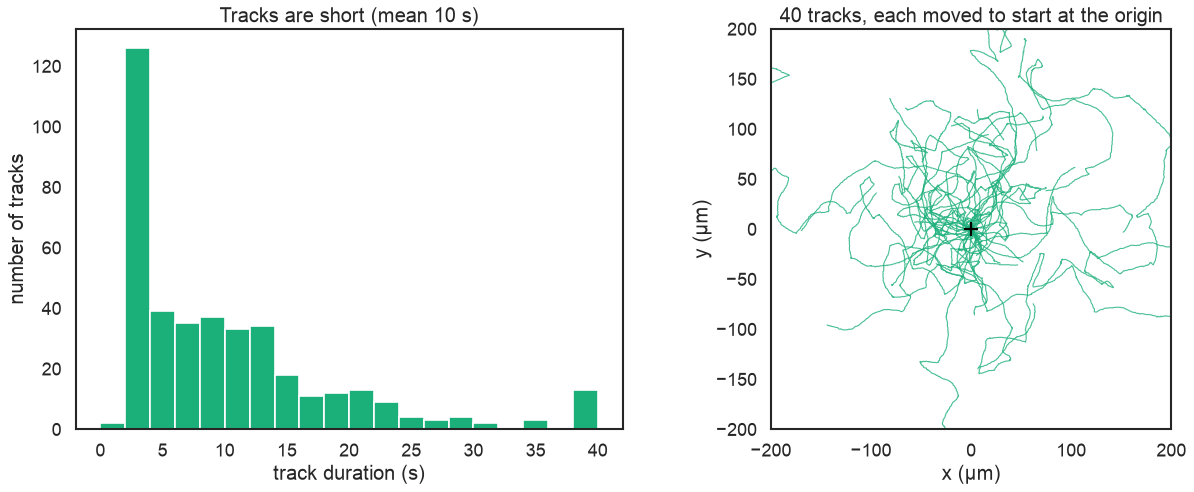

In [4]:
durations = df.groupby("track_id")["t"].agg(lambda t: t.max() - t.min())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))
ax1.hist(durations, bins=np.arange(0, 42, 2), color=COLORS["run_tumble"])
ax1.set(xlabel="track duration (s)", ylabel="number of tracks",
        title=f"Tracks are short (mean {durations.mean():.0f} s)")

for tid, g in list(df.groupby("track_id"))[:40]:
    xy = g[["x_um", "y_um"]].to_numpy()
    ax2.plot(xy[:, 0] - xy[0, 0], xy[:, 1] - xy[0, 1], color=COLORS["run_tumble"], lw=1, alpha=0.8)
ax2.plot(0, 0, "+", color="k", ms=12, mew=2)
ax2.set(xlim=(-200, 200), ylim=(-200, 200), aspect="equal", xlabel="x (µm)", ylabel="y (µm)",
        title="40 tracks, each moved to start at the origin")
fig.tight_layout()
plt.show()

## 2 · A · Speeds

### 2.1 Velocity from noisy positions
The simplest estimate is the displacement between consecutive frames divided by the time step:
$$\mathbf v_n=\frac{\mathbf r_{n+1}-\mathbf r_n}{\Delta t},\qquad \Delta t=\frac{1}{\text{fps}},\qquad v_n=|\mathbf v_n|\ \ \text{(the speed)}.$$
Every position has an error $\sigma\approx0.2$ µm. The difference of two positions has error $\sqrt2\,\sigma$, and dividing by $\Delta t=1/30$ s multiplies it by 30: each velocity component gets a noise $\sigma_v=\sqrt2\,\sigma/\Delta t\approx8.5$ µm/s, a third of the swimming speed.

A **Savitzky–Golay filter** reduces this. It fits a parabola to the positions in a window of $w$ frames and takes its slope at the center. A wider window removes more noise but blurs events shorter than the window, and a tumble lasts only 0.15 s, or 4–5 frames.

Below: this trade-off on the longest track of the dataset. Gray bands mark the frames in which the cell is truly tumbling.

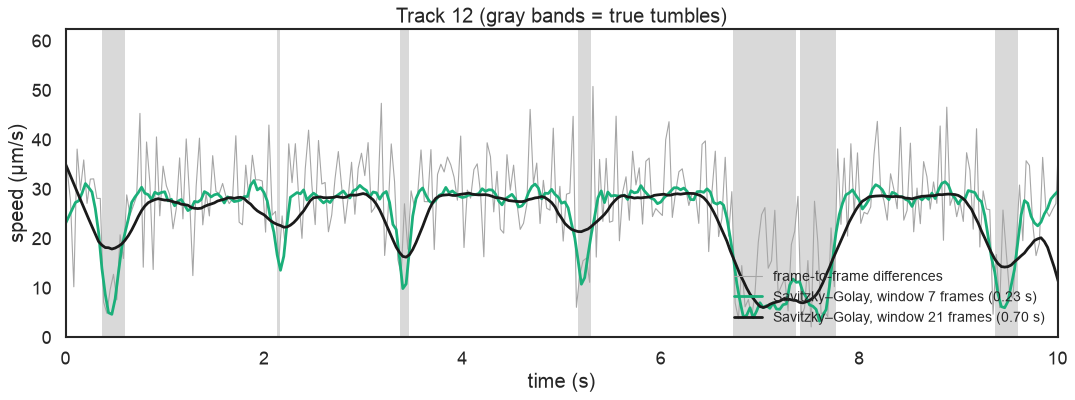

In [5]:
TID = durations.idxmax()                              # the longest track
one = df[df.track_id == TID].sort_values("frame")
t1 = one["t"].to_numpy() - one["t"].iloc[0]           # time since the start of the track (s)
tumbling1 = one.merge(truth, on=["track_id", "frame"])["state"].eq("tumble").to_numpy()

def shade_tumbles(ax, t, tumbling):
    """Draw gray bands where the cell is truly tumbling."""
    edges = np.diff(np.r_[0, tumbling.astype(int), 0])
    for start, stop in zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)):
        ax.axvspan(t[start], t[stop - 1] + 1 / FPS, color="0.85", lw=0, zorder=0)

xy1 = one[["x_um", "y_um"]].to_numpy()
speed_raw = np.hypot(*(np.diff(xy1, axis=0) * FPS).T)        # frame-to-frame speed (µm/s)

T_SHOW = 10                                           # s of the track to show
fig, ax = plt.subplots(figsize=(16, 5))
shade_tumbles(ax, t1, tumbling1)
ax.plot(t1[:-1] + 0.5 / FPS, speed_raw, color="0.65", lw=1, label="frame-to-frame differences")
for w, color in [(7, COLORS["run_tumble"]), (21, "0.1")]:
    k = an.kinematics(one, FPS, window=w)
    ax.plot(k["t"] - one["t"].iloc[0], k["speed"], color=color, lw=2.5, label=f"Savitzky–Golay, window {w} frames ({w / FPS:.2f} s)")
ax.set(xlim=(0, T_SHOW), ylim=(0, None), xlabel="time (s)", ylabel="speed (µm/s)",
       title=f"Track {TID} (gray bands = true tumbles)")
ax.legend(fontsize="x-small", loc="lower right")
plt.show()

### 🔧 Try it 2 · Tune the smoothing by hand
> Open `notebooks/smoothing_explorer.html`. In JupyterLab, double-click it and then click **Trust HTML** in the toolbar, so the page may run its script. Or open the file in any web browser; no Python needed. It shows a synthetic swimmer with the same noise as our data, so the error of every estimate is known.
>
> 1. Click **Raw difference**, then drag the window slider up from 5 frames. Watch the noise and the tumbles (the dips).
> 2. In the lower chart, find where the **noise** and **bias** curves cross. Why does the total error have a minimum?
> 3. Set the polynomial order to 4. Does the best window move? Which way?
> 4. Set the noise σ to 0.5 µm (dimmer cells, worse camera). Where does the best window go?
>
> **Discuss: choosing the hyperparameters for real data.** Window and order are not fitted. They follow from the localization noise σ (measure it from stuck cells, or see NB2 section 7) and from the shortest event to keep (a tumble, 0.15 s). The best window is a *duration*: 0.2–0.3 s is 7–9 frames at 30 fps but 20–30 frames at 100 fps.

We use **7 frames (0.23 s)**: the noise drops from 8.5 to about 1 µm/s per component, and a tumble still shows as a clear dip. `an.kinematics` computes velocity, speed, heading and angular velocity for every frame of every track.

In [6]:
WINDOW = 7            # 🔧 frames. After Try it 2 you may change it here and re-run the cells below
kin = an.kinematics(df, FPS, window=WINDOW)           # velocity, speed, heading, angular velocity of every frame
kin = kin.merge(truth, on=["track_id", "frame"])      # add the true state (synthetic data only)
print(f"velocity noise per component: {an.velocity_noise(SIGMA, FPS):.1f} µm/s from frame-to-frame differences, "
      f"{an.velocity_noise(SIGMA, FPS, WINDOW):.1f} µm/s after smoothing")

kin.head()

velocity noise per component: 8.5 µm/s from frame-to-frame differences, 1.1 µm/s after smoothing


,track_id,frame,t,vx,vy,speed,heading,omega,state
0,1,248,8.2667,20.286429,-17.261786,26.636599,-0.705018,1.143327,run
1,1,249,8.3000,20.425000,-16.046786,25.974602,-0.665926,1.202348,run
2,1,250,8.3333,20.563571,-14.831786,25.354336,-0.624856,1.261896,run
3,1,251,8.3667,20.702143,-13.616786,24.778934,-0.581802,1.321182,run
4,1,252,8.4000,21.883929,-11.658214,24.795570,-0.489487,2.660985,run


### 2.2 Angular velocity
The **angular velocity** $\omega=d\theta/dt$ is how fast the swimming direction turns. From the smoothed velocity $\mathbf v$ and acceleration $\mathbf a$:
$$\omega=\frac{v_x a_y-v_y a_x}{|\mathbf v|^2}\quad(\text{rad/s}).$$

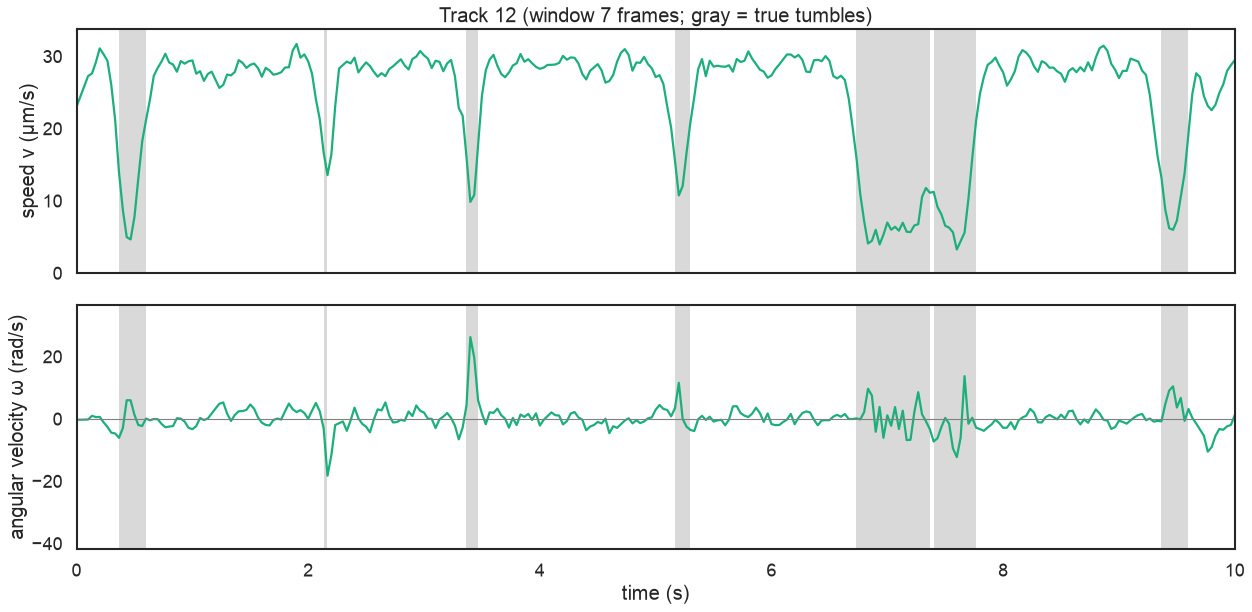

In [7]:
k1 = kin[kin.track_id == TID]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for ax in (ax1, ax2):
    shade_tumbles(ax, t1, tumbling1)
ax1.plot(k1["t"] - one["t"].iloc[0], k1["speed"], color=COLORS["run_tumble"], lw=2)
ax2.plot(k1["t"] - one["t"].iloc[0], k1["omega"], color=COLORS["run_tumble"], lw=2)
ax2.axhline(0, color="0.5", lw=1)
ax1.set(ylabel="speed v (µm/s)", ylim=(0, None), title=f"Track {TID} (window {WINDOW} frames; gray = true tumbles)")
ax2.set(xlim=(0, T_SHOW), xlabel="time (s)", ylabel="angular velocity ω (rad/s)")
fig.tight_layout()
plt.show()

During a tumble the speed drops **and** the cell turns fast.

### 2.3 Distributions of speed and angular velocity
All frames of all cells, split by their true state:

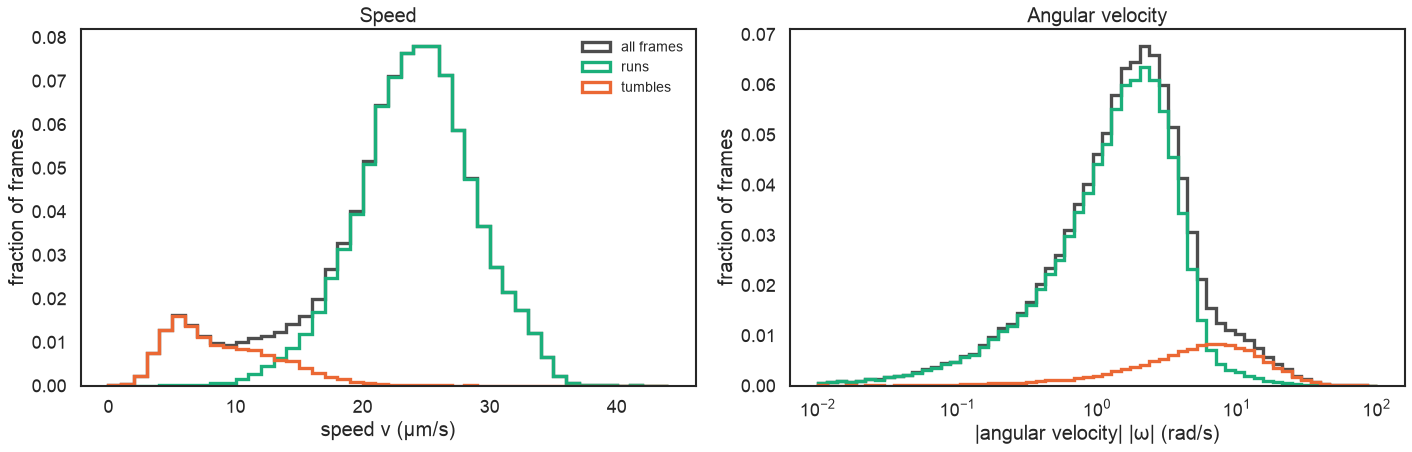

13% of the frames are tumbles


In [8]:
runs, tumbles = kin[kin.state == "run"], kin[kin.state == "tumble"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
for data, label, color in [(kin, "all frames", "0.3"), (runs, "runs", COLORS["run_tumble"]),
                           (tumbles, "tumbles", COLORS["biased"])]:
    weight = np.full(len(data), 1 / len(kin))         # fractions of all frames, so runs + tumbles = all
    ax1.hist(data["speed"], bins=np.arange(0, 45, 1), weights=weight, histtype="step", lw=3, color=color, label=label)
    ax2.hist(data["omega"].abs(), bins=np.logspace(-2, 2, 60), weights=weight, histtype="step", lw=3, color=color)
ax1.set(xlabel="speed v (µm/s)", ylabel="fraction of frames", title="Speed")
ax2.set(xscale="log", xlabel="|angular velocity| |ω| (rad/s)", ylabel="fraction of frames", title="Angular velocity")
ax1.legend(fontsize="x-small")
fig.tight_layout()
plt.show()
print(f"{len(tumbles) / len(kin):.0%} of the frames are tumbles")

Runs are fast and turn slowly; tumbles are slow and turn fast. But each distribution alone overlaps: a slow run looks like a tumble in speed, and a wobbly run looks like one in angular velocity.

### 2.4 Differences between individuals: real, or noise?
Each cell has its own mean speed. Before calling the differences *variability*, we need the **error** of each mean. Neighboring frames are correlated (we smoothed them), so `an.track_summary` cuts each track into 1 s blocks and uses the scatter of the block means.

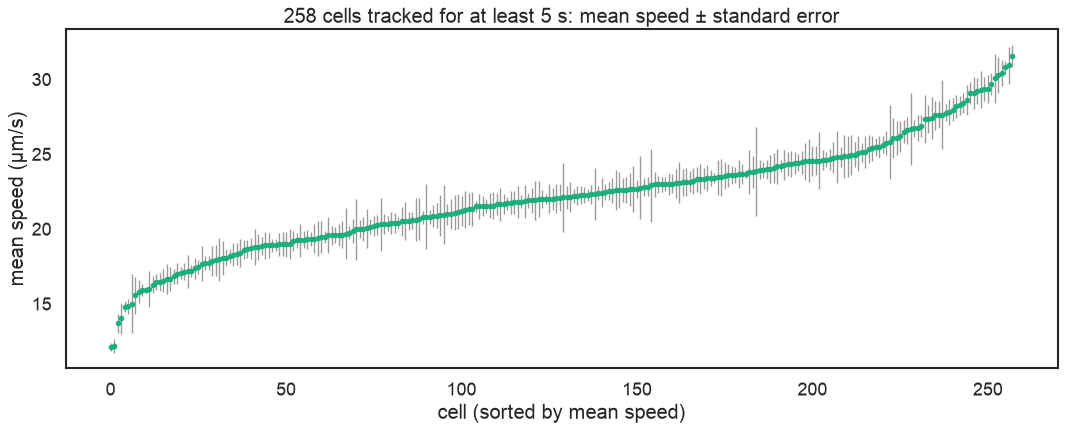

spread of the cell means (standard deviation): 3.6 µm/s
typical error of one cell's mean:              0.8 µm/s


In [9]:
summary = an.track_summary(kin, FPS, block_s=1.0)
summary = summary[summary.duration_s >= 5].sort_values("mean_speed").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(16, 5.5))
ax.errorbar(np.arange(len(summary)), summary["mean_speed"], yerr=summary["sem_speed"], fmt="o", ms=4,
            color=COLORS["run_tumble"], ecolor="0.6", elinewidth=1.2)
ax.set(xlabel="cell (sorted by mean speed)", ylabel="mean speed (µm/s)",
       title=f"{len(summary)} cells tracked for at least 5 s: mean speed ± standard error")
plt.show()

spread, error = summary["mean_speed"].std(), summary["sem_speed"].median()
print(f"spread of the cell means (standard deviation): {spread:.1f} µm/s")
print(f"typical error of one cell's mean:              {error:.1f} µm/s")

The cell means are spread far more widely than their error bars: the differences are **real**. (In this dataset each cell was given its own speed, with standard deviation `speed_sd` = 4 µm/s.)

### 🔧 Try it 3 · Noise or individuality?
> The figure says the cells differ. Question the error bars before trusting it.
>
> 1. Set `BLOCK_S_TRY = 0.033` (single frames): the error shrinks. Is that honest? (Smoothed frames are not independent.)
> 2. Set `BLOCK_S_TRY = 3`. What happens to the error, and to the number of cells that get one?
> 3. Change `MIN_DURATION_S`. Do short tracks make the spread look larger or smaller?
>
> **Discuss.** What would the figure look like if all cells were identical? Besides noise, what makes clonal cells differ in speed (growth phase, flagella, size)? We measure a spread of 3.6 µm/s, not the built-in 4, because each mean includes the cell's slow tumble frames.

In [10]:
BLOCK_S_TRY = 1.0        # 🔧 block length for the error bars (s). Try 0.033 (single frames), 0.3 and 3
MIN_DURATION_S = 5       # 🔧 keep cells tracked at least this long (s). Try 2 and 15

s_try = an.track_summary(kin, FPS, block_s=BLOCK_S_TRY)
s_try = s_try[s_try.duration_s >= MIN_DURATION_S]
spread, error = s_try["mean_speed"].std(), s_try["sem_speed"].median()
print(f"{len(s_try)} cells tracked for at least {MIN_DURATION_S} s; blocks of {BLOCK_S_TRY} s, "
      f"{s_try['n_blocks'].median():.0f} blocks per cell, {s_try['sem_speed'].notna().sum()} cells with an error bar")
print(f"spread of the cell means: {spread:.1f} µm/s    typical error of one mean: {error:.1f} µm/s    ratio {spread / error:.0f}")

258 cells tracked for at least 5 s; blocks of 1.0 s, 12 blocks per cell, 258 cells with an error bar
spread of the cell means: 3.6 µm/s    typical error of one mean: 0.8 µm/s    ratio 4


## 3 · B · The (v, ω) state space

Speed and angular velocity separate runs and tumbles better **together**. Every frame is a point in the $(\omega, v)$ plane; we count the frames in each small square (darker = more frames, log scale).

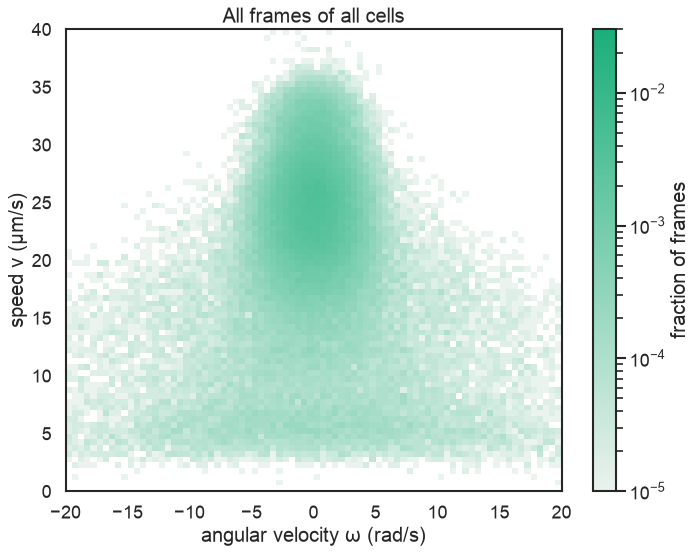

In [11]:
from matplotlib.colors import LogNorm

W_RANGE, V_RANGE = (-20, 20), (0, 40)                 # rad/s, µm/s
BINS = [np.linspace(*W_RANGE, 81), np.linspace(*V_RANGE, 81)]

def state_space(ax, frames, color, title):
    """2D histogram of (omega, speed); frames outside the ranges are left out."""
    counts, w_edges, v_edges = np.histogram2d(frames["omega"], frames["speed"], bins=BINS)
    im = ax.pcolormesh(w_edges, v_edges, counts.T / len(kin), cmap=sns.light_palette(color, as_cmap=True),
                       norm=LogNorm(1e-5, 3e-2), rasterized=True)
    ax.set(xlabel="angular velocity ω (rad/s)", title=title)
    return im

fig, ax = plt.subplots(figsize=(10, 7.5))
im = state_space(ax, kin, COLORS["run_tumble"], "All frames of all cells")
ax.set_ylabel("speed v (µm/s)")
fig.colorbar(im, ax=ax, label="fraction of frames")
plt.show()

The frames fill two regions: a dense band at high speed and small $\omega$, and a diffuse cloud at low speed and large $|\omega|$. Are these the two states? Check with the truth:

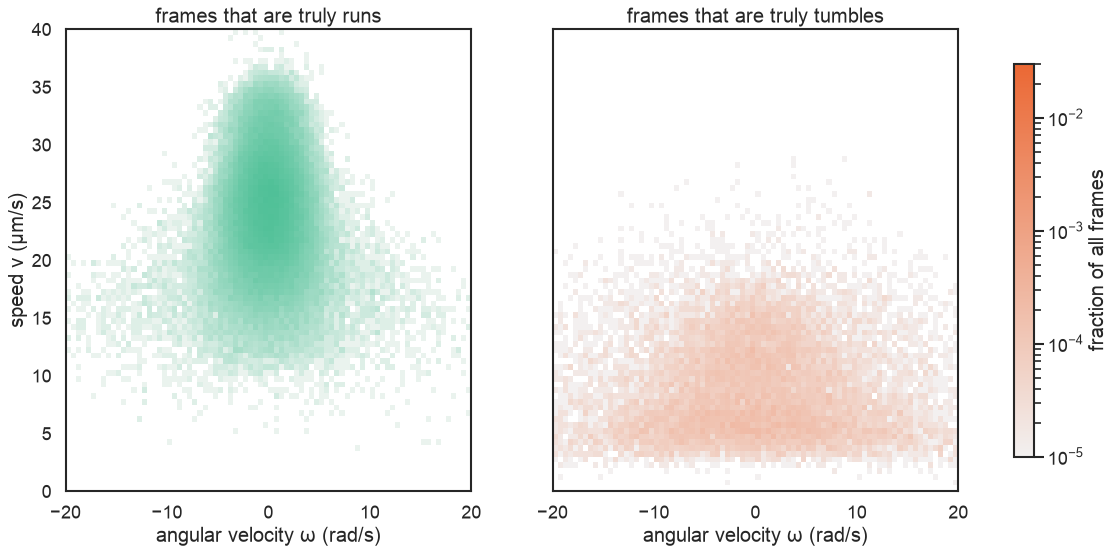

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), sharey=True)
state_space(axes[0], runs, COLORS["run_tumble"], "frames that are truly runs")
im = state_space(axes[1], tumbles, COLORS["biased"], "frames that are truly tumbles")
axes[0].set_ylabel("speed v (µm/s)")
fig.colorbar(im, ax=axes, label="fraction of all frames", shrink=0.85)
plt.show()

Runs and tumbles occupy different regions, but the regions overlap: the start and end of a tumble look like a slow run, and smoothing mixes neighboring frames.

### 🔧 Try it 4 · Detect and define states
> The simplest detector is a rule in the $(v,\omega)$ plane: a frame is a tumble if the cell is slower than `V_MAX` **or** turns faster than `W_MIN`. Against the truth, **recall** is the fraction of true tumble frames found, and **precision** the fraction of called frames that are true tumbles.
>
> 1. Run the two cells below as they are. In the track on the right, where are the errors: inside tumbles, at their edges, or during runs?
> 2. Change `V_MAX` and `W_MIN`. Can you get both above 80%? Which threshold does what?
> 3. Set `RULE = "and"`. What happens? Which rule would you use to count tumbles per second, and which to measure run durations?
>
> **Discuss.** A *state* is a region of the state space plus a rule. The regions overlap, so every rule makes errors, and the right rule depends on the question. Better detectors (smoothing the state sequence in time, hidden Markov models, clustering) are a project direction.

In [13]:
V_MAX = 15.0     # 🔧 µm/s: slower than this is a tumble
W_MIN = 5.0      # 🔧 rad/s: turning faster than this is a tumble
RULE = "or"     # 🔧 "or": either condition is enough;  "and": both are needed

rule: tumble if v < 15.0 µm/s OR |ω| > 5.0 rad/s
recall 95% (true tumble frames found),  precision 68% (called frames that are true tumbles)
tumble frames: 13.0% in truth, 18.1% called


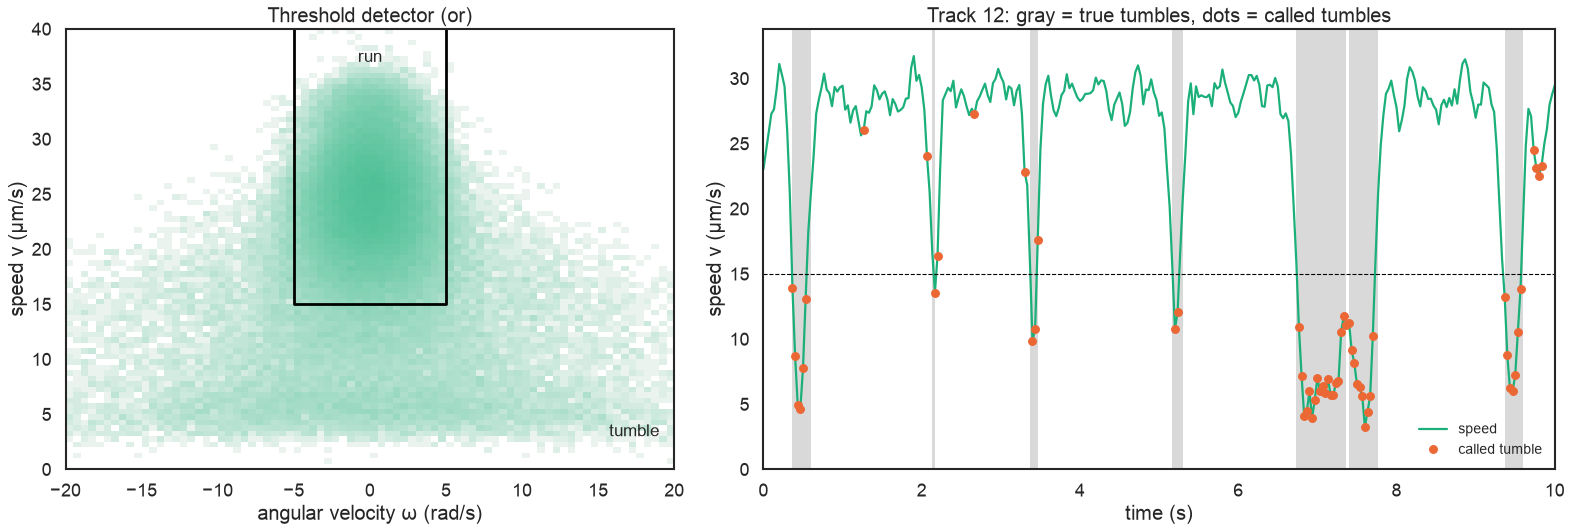

In [14]:
slow, turning = kin["speed"] < V_MAX, kin["omega"].abs() > W_MIN
called = (slow | turning) if RULE == "or" else (slow & turning)
true = kin["state"] == "tumble"
recall = (called & true).sum() / true.sum()
precision = (called & true).sum() / called.sum()
print(f"rule: tumble if v < {V_MAX} µm/s {RULE.upper()} |ω| > {W_MIN} rad/s")
print(f"recall {recall:.0%} (true tumble frames found),  precision {precision:.0%} (called frames that are true tumbles)")
print(f"tumble frames: {true.mean():.1%} in truth, {called.mean():.1%} called")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 7), width_ratios=[1, 1.3])
state_space(ax1, kin, COLORS["run_tumble"], f"Threshold detector ({RULE})")
if RULE == "or":
    ax1.plot([-W_MIN, -W_MIN, W_MIN, W_MIN], [V_RANGE[1], V_MAX, V_MAX, V_RANGE[1]], color="k", lw=2.5)
else:
    for s in (-1, 1):
        ax1.plot([s * W_MIN, s * W_MIN, s * W_RANGE[1]], [0, V_MAX, V_MAX], color="k", lw=2.5)
ax1.text(0, V_RANGE[1] - 3, "run", ha="center", fontsize="small")
ax1.text(W_RANGE[1] - 1, 3, "tumble", ha="right", fontsize="small")
ax1.set_ylabel("speed v (µm/s)")

# the example track: true tumbles (gray bands) against the frames the rule calls tumbles (orange dots)
k1 = kin[kin.track_id == TID]
tt = k1["t"] - one["t"].iloc[0]
c1 = called[k1.index]
shade_tumbles(ax2, t1, tumbling1)
ax2.plot(tt, k1["speed"], color=COLORS["run_tumble"], lw=2, label="speed")
ax2.plot(tt[c1], k1["speed"][c1], "o", ms=7, color=COLORS["biased"], label="called tumble")
ax2.axhline(V_MAX, color="k", lw=1, ls="--")
ax2.set(xlim=(0, T_SHOW), ylim=(0, None), xlabel="time (s)", ylabel="speed v (µm/s)",
        title=f"Track {TID}: gray = true tumbles, dots = called tumbles")
ax2.legend(fontsize="x-small", loc="lower right")
fig.tight_layout()
plt.show()

## 4 · C · Correlations: how long does a cell remember?

A cell keeps its direction during a run and loses it at a tumble. The **autocorrelation** measures this memory: how similar is a quantity now to the same quantity a time $\tau$ later, averaged over all cells and times?

We use the **orientation autocorrelation**, $C_\theta(\tau)=\langle\hat{\mathbf u}(t)\cdot\hat{\mathbf u}(t+\tau)\rangle=\langle\cos[\theta(t+\tau)-\theta(t)]\rangle$, where $\hat{\mathbf u}=\mathbf v/|\mathbf v|$ is the unit vector along the velocity. It ignores speed. (The *velocity* autocorrelation $\langle\mathbf v(t)\cdot\mathbf v(t+\tau)\rangle$ is $v^2C_\theta(\tau)$ for a cell at constant speed $v$; NB2 uses it to build the MSD.)

**Intuition: two time scales.** Two processes erase the direction, each at its own rate. Tumbles happen at random times at a constant rate $\lambda$ (a Poisson process), and each keeps on average a fraction $\langle\cos\varphi\rangle$ of the direction, so tumbles alone erase it at rate $\lambda\,(1-\langle\cos\varphi\rangle)$. Rotational diffusion wobbles the direction continuously and alone erases it at rate $D_r$. Each process by itself gives an exponential decay, and because both are memoryless, the two rates add:
$$C_\theta(\tau)=e^{-\tau/\tau_p},\qquad \frac{1}{\tau_p}=\lambda\,(1-\langle\cos\varphi\rangle)+D_r .$$
$\tau_p$ is the **persistence time**: how long the cell remembers its direction. The formula treats tumbles as instantaneous and is for motion in 2D. For cells tracked in 3D the last term is $2D_r$, because the direction can wobble in two independent ways. The derivation is in Lovely & Dahlquist (1975) and, with persistence of direction, in Locsei (2007).

**Measuring $\tau_p$.** For real data we do not know $\lambda$, $\varphi$ or $D_r$. We measure $\tau_p$ directly by fitting an exponential to $C_\theta(\tau)$: a straight line on a log axis. Our data are synthetic, so we can also compute $\tau_p$ from the formula and compare.

> **References.** Lovely PS, Dahlquist FW (1975) Statistical measures of bacterial motility and chemotaxis. *J Theor Biol* 50:477–496. Locsei JT (2007) Persistence of direction increases the drift velocity of run and tumble chemotaxis. *J Math Biol* 55:41–60. Berg HC (1993) *Random Walks in Biology*, Princeton University Press.

fitted from C_θ(τ):  τ_p = 1.21 s
formula, with the simulation parameters λ = 1.0/s, <cos φ> = 0.31, D_r = 0.15/s:  τ_p = 1.19 s


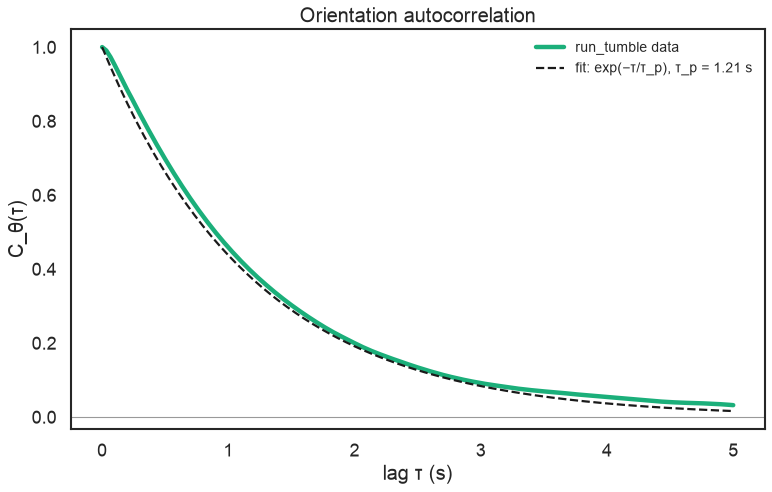

In [15]:
MAX_LAG = int(5 * FPS)                                # frames (5 s)
lag_t = np.arange(MAX_LAG + 1) / FPS
FIT_MAX_S = 2.0                                       # fit the exponential to lags up to 2 s (longer lags: few pairs, noisy)

def orientation_autocorrelation(kin):
    """C_θ(τ) averaged over all cells and times, and the number of frame pairs at each lag."""
    vel = [g[["vx", "vy"]].to_numpy() for _, g in kin.groupby("track_id")]
    unit = [v / np.linalg.norm(v, axis=1, keepdims=True) for v in vel]
    return an.autocorrelation(unit, MAX_LAG)

def fit_tau_p(C):
    """Persistence time: slope of a straight-line fit to log C(τ) for 0 < τ <= FIT_MAX_S."""
    sel = (lag_t > 0) & (lag_t <= FIT_MAX_S)
    slope = np.polyfit(lag_t[sel], np.log(C[sel]), 1)[0]
    return -1 / slope

Cu, n_pairs = orientation_autocorrelation(kin)
tau_p = fit_tau_p(Cu)

cos_phi = sim.turn_angle_cos(params["turn_angle"])
tau_p_formula = 1 / (params["run_rate"] * (1 - cos_phi) + params["Dr"])
print(f"fitted from C_θ(τ):  τ_p = {tau_p:.2f} s")
print(f"formula, with the simulation parameters λ = {params['run_rate']}/s, <cos φ> = {cos_phi:.2f}, "
      f"D_r = {params['Dr']}/s:  τ_p = {tau_p_formula:.2f} s")

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot(lag_t, Cu, lw=4, label="run_tumble data", **STYLE["run_tumble"])
ax.plot(lag_t, np.exp(-lag_t / tau_p), ls="--", label=f"fit: exp(−τ/τ_p), τ_p = {tau_p:.2f} s", **THEORY_KW)
ax.axhline(0, color="0.6", lw=1)
ax.set(xlabel="lag τ (s)", ylabel="C_θ(τ)", title="Orientation autocorrelation")
ax.legend(fontsize="x-small")
fig.tight_layout()
plt.show()

The exponential fits the orientation autocorrelation well. The fitted $\tau_p$ is slightly longer than the formula's value: real tumbles take 0.15 s, during which no new tumble can start and the turn is spread out, so the cell keeps its direction a little longer.

### 4.1 A tumble rate that drifts over time (OU switching)
In real *E. coli* the tumble rate of one cell is not constant: it follows a signaling protein (CheY-P) that fluctuates slowly. We let the rate drift,
$$\lambda(t)=\lambda\,e^{\,x(t)-\sigma^2/2},$$
where $x(t)$ is an **Ornstein–Uhlenbeck (OU) process**: a random signal with standard deviation $\sigma$ that forgets its value after a correlation time $\tau_x$. The factor $e^{-\sigma^2/2}$ keeps the average rate at $\lambda$. We simulate cells identical to the dataset except for this drift ($\sigma=1$, $\tau_x=10$ s), make a dataset the same way, and analyze it as above.

### 🔧 Try it 5 · Predict, then run
> Before running the next two cells, write down:
> 1. The *average* tumble rate is unchanged. Will the correlation decay faster, slower, or the same?
> 2. Will it still be a straight line on the log axis?
>
> Run and check. Then set `OU_TAU = 0.3` (the rate fluctuates much faster than a run lasts), predict again, and run. Then set `OU_SIGMA = 0`.

In [16]:
OU_SIGMA, OU_TAU = 1.0, 10.0   # 🔧 size σ and correlation time τ_x (s) of the tumble-rate fluctuations. Try τ_x = 0.3, then σ = 0

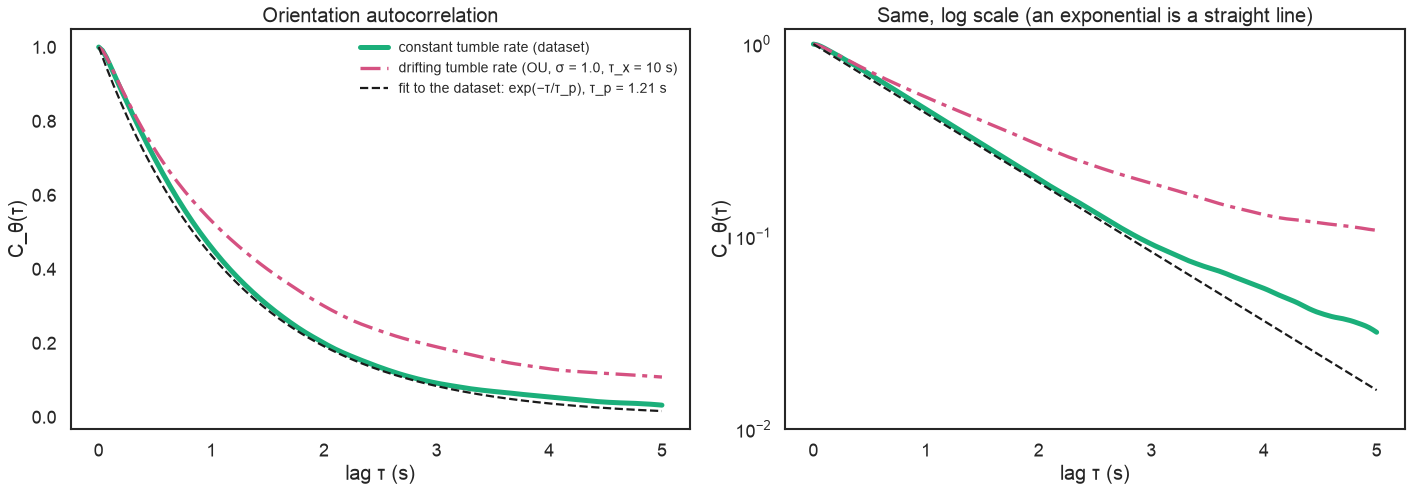

In [17]:
positions, states, _ = sim.simulate_run_tumble(400, 40, FPS, rng, **params, ou_sigma=OU_SIGMA, ou_tau=OU_TAU)
df_ou, truth_ou = sim.as_dataset(positions, FPS, rng, states=states, sigma_loc=SIGMA)
kin_ou = an.kinematics(df_ou, FPS, window=WINDOW)
Cu_ou, _ = orientation_autocorrelation(kin_ou)

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
axes[1].set_yscale("log")
for ax in axes:
    ax.plot(lag_t, Cu, lw=4.5, label="constant tumble rate (dataset)", **STYLE["run_tumble"])
    ax.plot(lag_t, Cu_ou, lw=3, label=f"drifting tumble rate (OU, σ = {OU_SIGMA}, τ_x = {OU_TAU:g} s)", **STYLE["ou"])
    ax.plot(lag_t, np.exp(-lag_t / tau_p), ls="--", label=f"fit to the dataset: exp(−τ/τ_p), τ_p = {tau_p:.2f} s", **THEORY_KW)
    ax.set(xlabel="lag τ (s)", ylabel="C_θ(τ)")
axes[0].set(title="Orientation autocorrelation")
axes[1].set(ylim=(1e-2, 1.2), title="Same, log scale (an exponential is a straight line)")
axes[0].legend(fontsize="x-small")
fig.tight_layout()
plt.show()

Cells with a drifting rate remember their direction much longer, although their average rate is the same: periods of low rate give long runs, and these dominate the memory at long lags. On the log scale the curve is no longer straight, so one persistence time no longer describes the population. **Variability within each cell over time changes the behavior of the whole population.** (NB2 shows the same effect in the MSD.)

**Discuss.**
1. A single $\tau_p$ describes a population with one tumble rate. Any heterogeneity, within a cell over time or between cells, slows and bends the decay.
2. With $\tau_x=10$ s and 10 s tracks, each track sees a nearly constant rate, so these data cannot tell drift within cells from differences between cells. What experiment could?
3. Why did $\tau_x=0.3$ s bring the curve back to the exponential?

> **How far can we trust long lags?** Pairs of frames 5 s apart exist only in tracks longer than 5 s, so long lags rest on fewer, and different, cells than short lags:

In [18]:
for lag in [0, 1, 2, 5]:
    print(f"lag {lag} s: {int(n_pairs[int(lag * FPS)]):>7d} pairs of frames")

lag 0 s:  123855 pairs of frames
lag 1 s:  111855 pairs of frames
lag 2 s:   99855 pairs of frames
lag 5 s:   73505 pairs of frames


## 5 · Summary and questions

* **A · Speeds.** Frame-to-frame speeds are dominated by localization noise (~8.5 µm/s per component at 30 fps). Smoothing trades noise against blurred short events. Differences between cells mean something only when they exceed the error of each estimate.
* **B · State space.** In the $(v,\omega)$ plane runs and tumbles occupy different regions: the starting point for state detection.
* **C · Correlations.** The autocorrelation measures memory of direction. A constant tumble rate gives an exponential with persistence time $\tau_p$; a drifting rate gives a longer, non-exponential memory.

**Questions**
1. How would you estimate the localization noise $\sigma$ of a real dataset? (Hint: NB2, section 7.)
2. Your camera runs at 10 fps instead of 30. What happens to the velocity noise, and to how well you can see tumbles?
3. *V. cholerae* does not move like *E. coli*: its navigation strategy is different. Which of the tools of this notebook (speed and angular velocity distributions, the $(v,\omega)$ plane, the orientation autocorrelation) would show the difference, and what would you look for in each?

**Next:** NB2 (part D): the mean squared displacement.